# Coverage Is Not Connectivity: New York's EV fast-charging network (final)

SSIE 641 final project: Joubin Zahiri Khameneh, Shamim Sharbaf, Zeinab Davoodmanesh.

This notebook walks through the results question by question. Every number comes from `scripts/run_all.py`,
which writes `results/tables/*.csv`, `results/figures/*.png` and `results/summary.json`. Set `RUN = True` to
rebuild everything (about three minutes). The analysis code lives in `src/evnet/`.

Changes from notebook v3 (`notebooks/ev_network_v3.ipynb`):
- Q3 uses a Steiner-tree heuristic (Takahashi & Matsuyama, 1980) with upper and lower bounds and an exact
  feasibility test, for two objectives (whole network, all city pairs), instead of the greedy search.
- Links to new stations use the measured detour factor 1.27, not 1.2; 1.2 is kept as a sensitivity check.
- "Big or small" is answered by ports as well as degree.
- Population share corrected: places with 5,000+ people hold 76% of the state, not 92%.
- New: budget against the $175M NEVI allocation, winter range, NYC-excluded and access-capped coverage,
  October 2026 data check.

In [1]:
import json, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUN = False
if RUN:
    subprocess.run([sys.executable, str(ROOT / "scripts" / "run_all.py")], check=True)

TAB, FIG = ROOT / "results" / "tables", ROOT / "results" / "figures"
S = json.load(open(ROOT / "results" / "summary.json"))
pd.set_option("display.max_colwidth", 120)
def t(name): return pd.read_csv(TAB / name)
def f(name): display(Image(filename=str(FIG / name), width=850))

## 1. Data

stations: 755 | fast ports: 3408 | sites: 754 | CCS sites: 661
places >= 5000: 362 | people: 15312729 | share of NY population: 75.8%
NYC's share of population-weighted city pairs: 73%
candidate L1/L2 locations: 4756
distances: straight line x 1.27 (road_miles.npy not found)


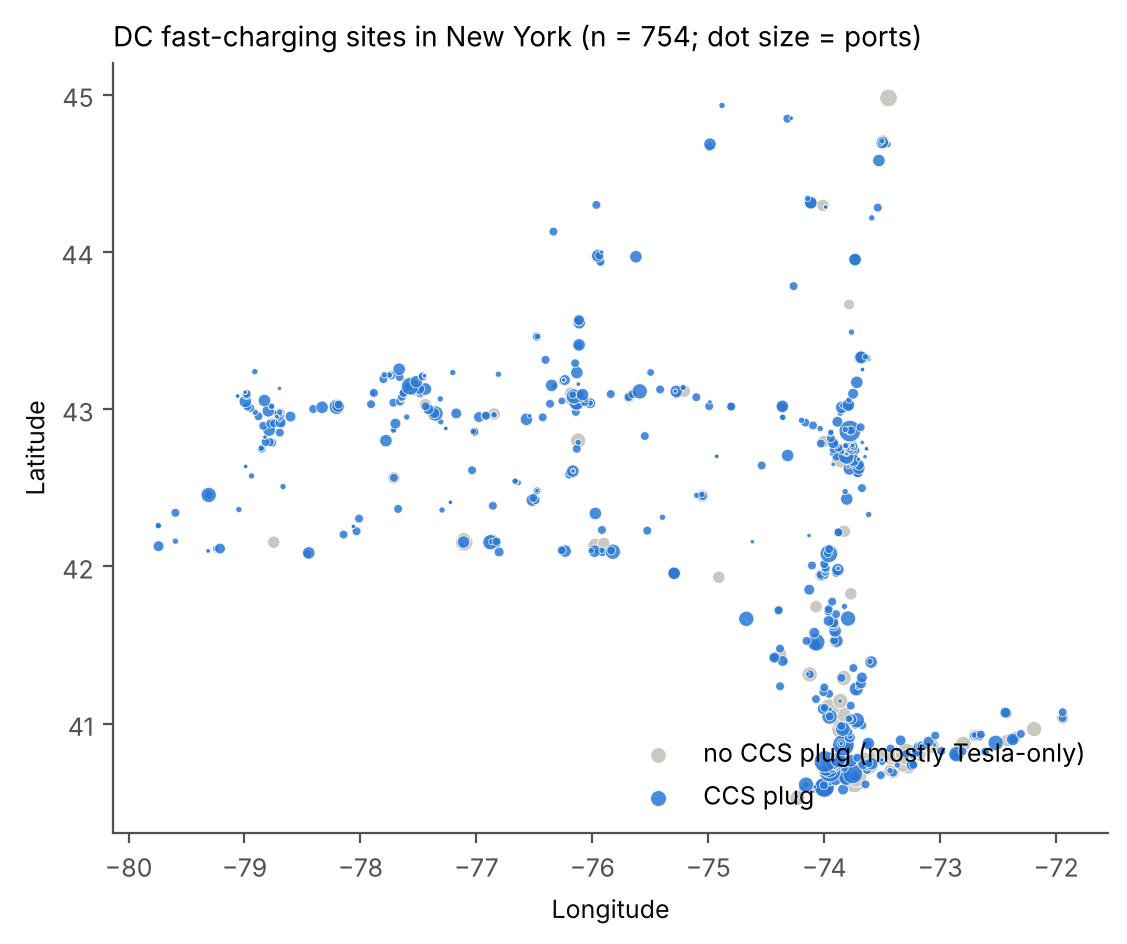

In [2]:
print("stations:", S["stations"], "| fast ports:", S["fast_ports"], "| sites:", S["sites"], "| CCS sites:", S["ccs_sites"])
print("places >= 5000:", S["places_5000"], "| people:", S["pop_places_5000"],
      f"| share of NY population: {S['share_state_pop_in_places_5000']:.1%}")
print(f"NYC's share of population-weighted city pairs: {S['nyc_share_of_pair_weight']:.0%}")
print("candidate L1/L2 locations:", S["candidates"])
print("distances:", S["distance_source"])
f("figS1_sites_map.png")

## 2. Q1: When does the network split?

The whole network is one piece from the longest link of its minimum spanning tree.
Road distances (notebook v3): 43.5 miles. Calibrated straight-line × 1.27 (this run): 45.6 miles.

{'all_calibrated': 45.6, 'all_straight_x1.2': 43.1, 'all_straight_xfactor': 45.6, 'ccs_calibrated': 45.6} | weakest link: Saranac Lake - Malone


,Unnamed: 0,all_calibrated,all_calibrated.1,all_calibrated.2,all_straight_x1.2,all_straight_x1.2.1,all_straight_x1.2.2,all_straight_xfactor,all_straight_xfactor.1,all_straight_xfactor.2,ccs_calibrated,ccs_calibrated.1,ccs_calibrated.2
0,NaN,miles,from,to,miles,from,to,miles,from,to,miles,from,to
1,0.0,45.63020712299764,Saranac Lake,Malone,43.11515633669068,Saranac Lake,Malone,45.63020712299764,Saranac Lake,Malone,45.63020712299764,Saranac Lake,Malone
2,1.0,35.82562218077972,Malone,Massena,33.85098158813832,Malone,Massena,35.82562218077972,Malone,Massena,40.52296721689728,Warrensburg,North Hudson
3,2.0,33.961560591229805,Pulaski,Watertown,32.08966355076832,Pulaski,Watertown,33.961560591229805,Pulaski,Watertown,36.64932435795496,Indian Lake,North Hudson
4,3.0,32.05771566185564,Chestertown,Indian Lake,30.290754956084065,Chestertown,Indian Lake,32.05771566185564,Chestertown,Indian Lake,35.82562218077972,Malone,Massena
5,4.0,27.861870785491863,Monticello,Roscoe,26.32617712014979,Monticello,Roscoe,27.861870785491863,Monticello,Roscoe,33.961560591229805,Pulaski,Watertown
6,5.0,27.38832088809958,Watertown,Cape Vincent,25.878728398204327,Watertown,Cape Vincent,27.38832088809958,Watertown,Cape Vincent,31.975275164853095,Arkville,TANNERSVILLE
7,6.0,27.37223973987284,Roscoe,Arkville,25.86353361247827,Roscoe,Arkville,27.37223973987284,Roscoe,Arkville,28.176546257666068,Hancock,Afton


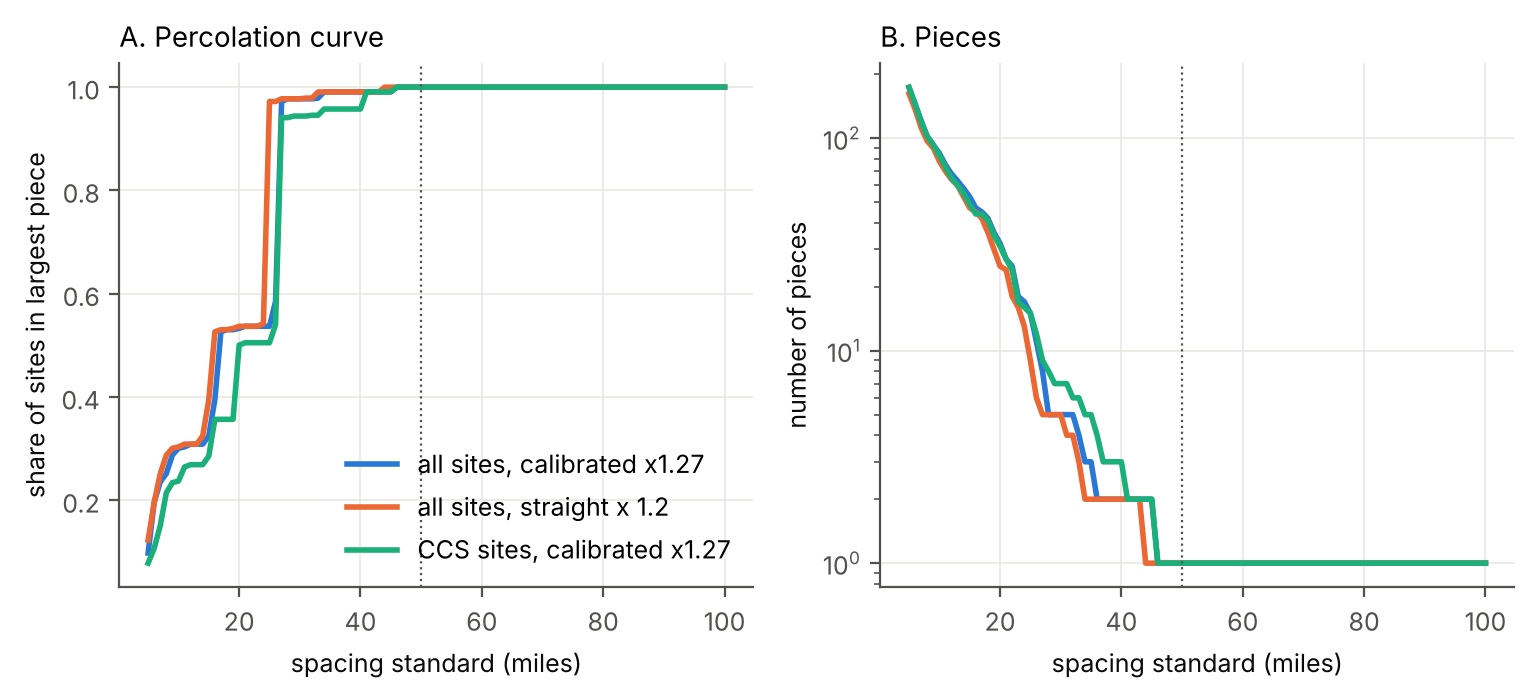

,piece,sites,mean_lat,mean_lon,main_cities
0,1,405,41.50,-73.71,"Queens, Albany, Brooklyn, New York, Latham, Riverhead"
1,2,280,42.88,-77.38,"Rochester, Syracuse, Buffalo, Niagara Falls, Yorkville, Elmira"
2,3,24,42.29,-75.61,"Binghamton, Vestal, Oneonta, Cooperstown, Owego, Kirkwood"
3,4,11,44.69,-73.50,"Plattsburgh, Peru"
4,5,8,44.30,-74.04,"Lake Placid, Saranac Lake"
5,6,7,43.97,-75.89,"Watertown, West Carthage"
6,7,5,44.73,-74.97,"Potsdam, Massena"
7,8,2,41.96,-75.29,Hancock
8,9,2,43.95,-73.73,North Hudson
9,10,2,44.25,-73.56,"Elizabethtown, Lewis"


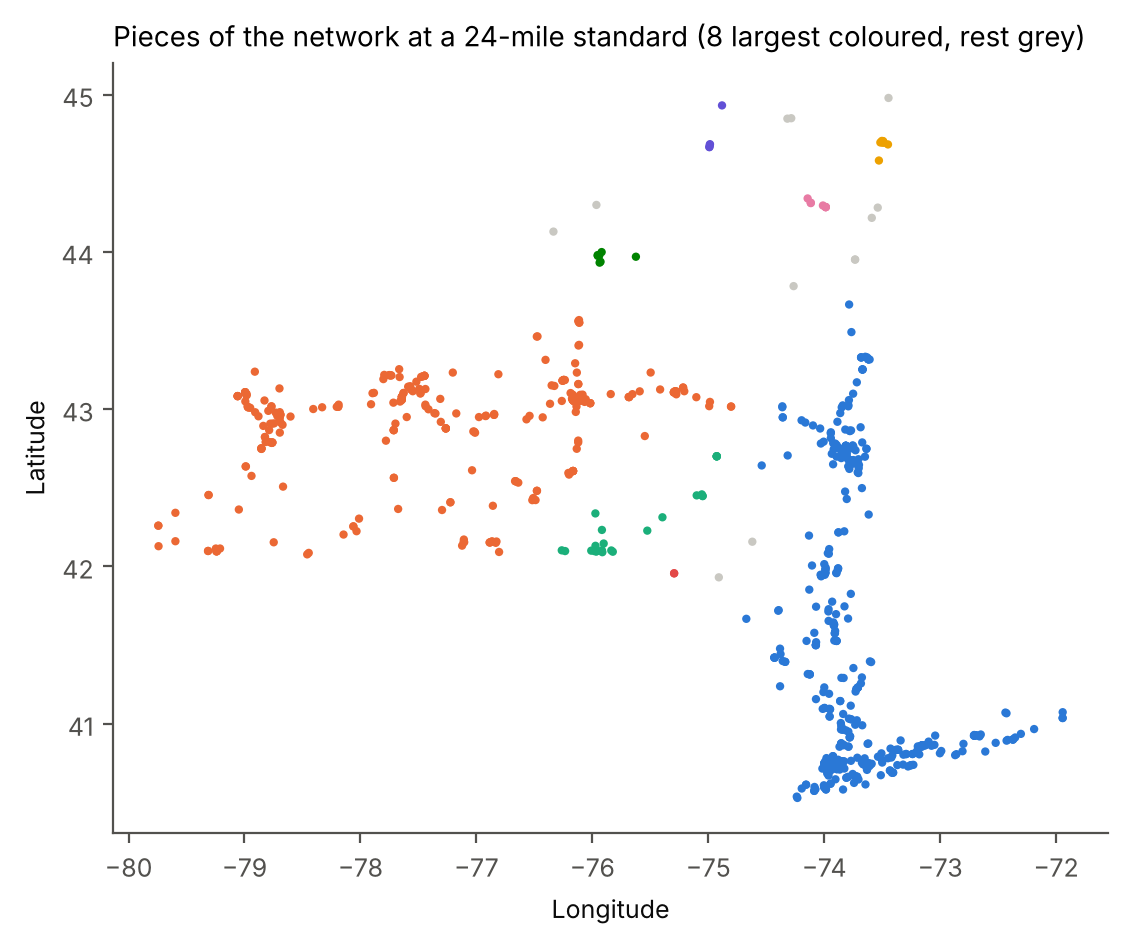

In [3]:
print({k: round(v, 1) for k, v in S["threshold"].items()}, "| weakest link:", S["weakest_link"])
display(t("q1_weakest_links.csv").head(8))
f("fig1_percolation.png")
display(t("q1_pieces_24mi.csv"))
f("fig2_pieces_24mi.png")

## 3. Q2: Which stations hold the network together?

Single points of failure (articulation points) are isolated rural sites: low degree, but typical or large by ports.

,network,miles,id,name,city,operator,degree,ports,sites_cut_off,degree_percentile,ports_percentile
0,all,30,707,Warren Ford,Warrensburg,FORD_CHARGE,16,2,25,0.181698,0.270557
1,all,30,712,"Chestertown, NY - Tesla Supercharger",Chestertown,Tesla,3,6,24,0.005305,0.701592
2,all,30,724,Egglefield Bros,Elizabethtown,FORD_CHARGE,8,2,21,0.058355,0.270557
3,all,30,725,EVolve NY Lewis,Lewis,Electrify America,7,4,12,0.050398,0.445623
4,all,30,735,"Peru, NY - Tesla Supercharger",Peru,Tesla,11,8,11,0.102122,0.774536
5,all,30,279,"Roscoe, NY - Tesla Supercharger",Roscoe,Tesla,4,8,1,0.014589,0.774536
6,ccs,30,636,EVolve NY Lewis,Lewis,Electrify America,6,4,10,0.039334,0.497731
7,ccs,30,645,"Peru, NY - Tesla Supercharger",Peru,Tesla,10,8,9,0.118003,0.857791
8,ccs,30,290,Simmons Rockwell Ford Hornell NY,Hornell,RED_E,8,4,7,0.074130,0.497731
9,ccs,30,138,EVolve NY Bridgehampton,Bridgehampton,Electrify America,19,4,2,0.225416,0.497731


,miles,network,critical_sites,median_degree_all,median_degree_critical,median_ports_all,median_ports_critical,share_tesla_critical
0,25,all,11,41.0,6.0,4.0,4.0,0.090909
1,25,ccs,9,36.0,5.0,4.0,4.0,0.000000
2,30,all,6,47.0,7.5,4.0,5.0,0.500000
3,30,ccs,6,43.0,8.0,4.0,4.0,0.166667
4,35,all,2,58.5,13.0,4.0,7.0,1.000000
5,35,ccs,2,53.0,18.5,4.0,4.5,0.500000
6,40,all,2,62.5,12.0,4.0,4.0,0.500000
7,40,ccs,1,59.0,5.0,4.0,2.0,0.000000
8,45,all,0,69.0,NaN,4.0,NaN,NaN
9,45,ccs,1,65.0,23.0,4.0,2.0,0.000000


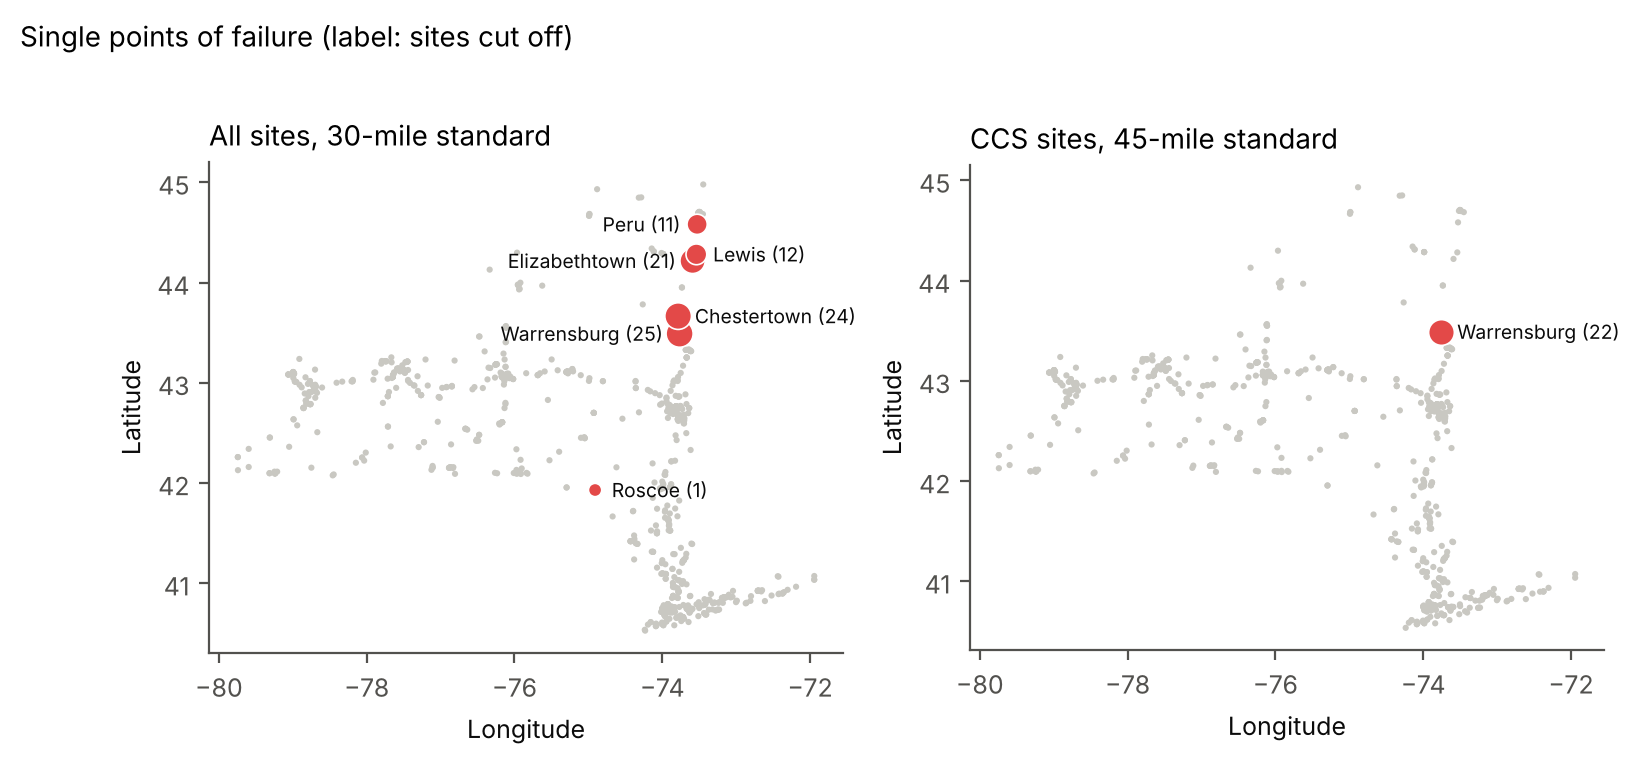

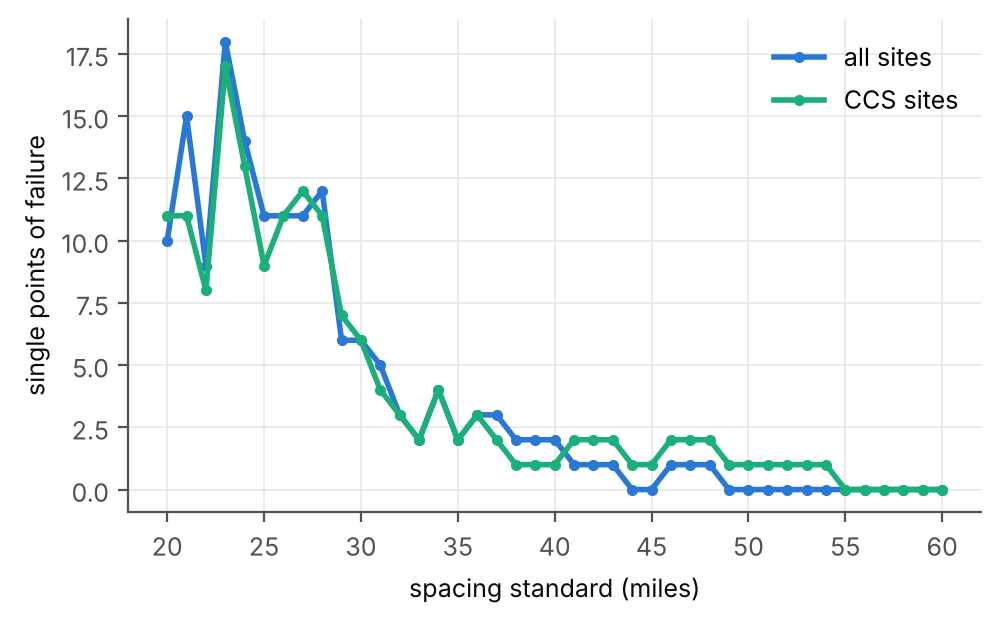

In [4]:
display(t("q2_critical_sites.csv"))
display(t("q2_big_or_small.csv"))
f("fig3_critical_sites.png")
f("figS2_cut_vertex_count.png")

### 3.1 Random failure and targeted attack

,network,miles,R_all,R_survivors,survivors_connected_p0.6
0,all,30,0.635175,0.882107,0.642854
1,all,35,0.667068,0.938739,0.786167
2,all,40,0.681207,0.966685,0.894008
3,all,45,0.688326,0.980224,0.953048
4,all,50,0.696312,0.992426,0.971574
5,ccs,30,0.613513,0.849225,0.624790
6,ccs,35,0.644942,0.904912,0.755426
7,ccs,40,0.662037,0.939143,0.870505
8,ccs,45,0.684521,0.973861,0.944610
9,ccs,50,0.691392,0.984210,0.960011


,miles,R_random,R_degree,R_betweenness,largest_after_15_betweenness,largest_after_30_betweenness,removals_to_drop_below_0.9
0,50,0.696312,0.677449,0.231372,0.980106,0.404509,18
1,30,0.635175,0.617779,0.156671,0.408488,0.397878,7


,degree,betweenness
0,Thornwood,Monticello
1,Hartsdale,Arkville
2,White Plains,Roscoe
3,White Plains,TANNERSVILLE
4,Tarrytown,Richmondville
5,Dobbs Ferry,Frankfort
6,Hastings on Hudson,Herkimer
7,Yonkers,Herkimer
8,Harrison,Schoharie
9,Yonkers,Rome


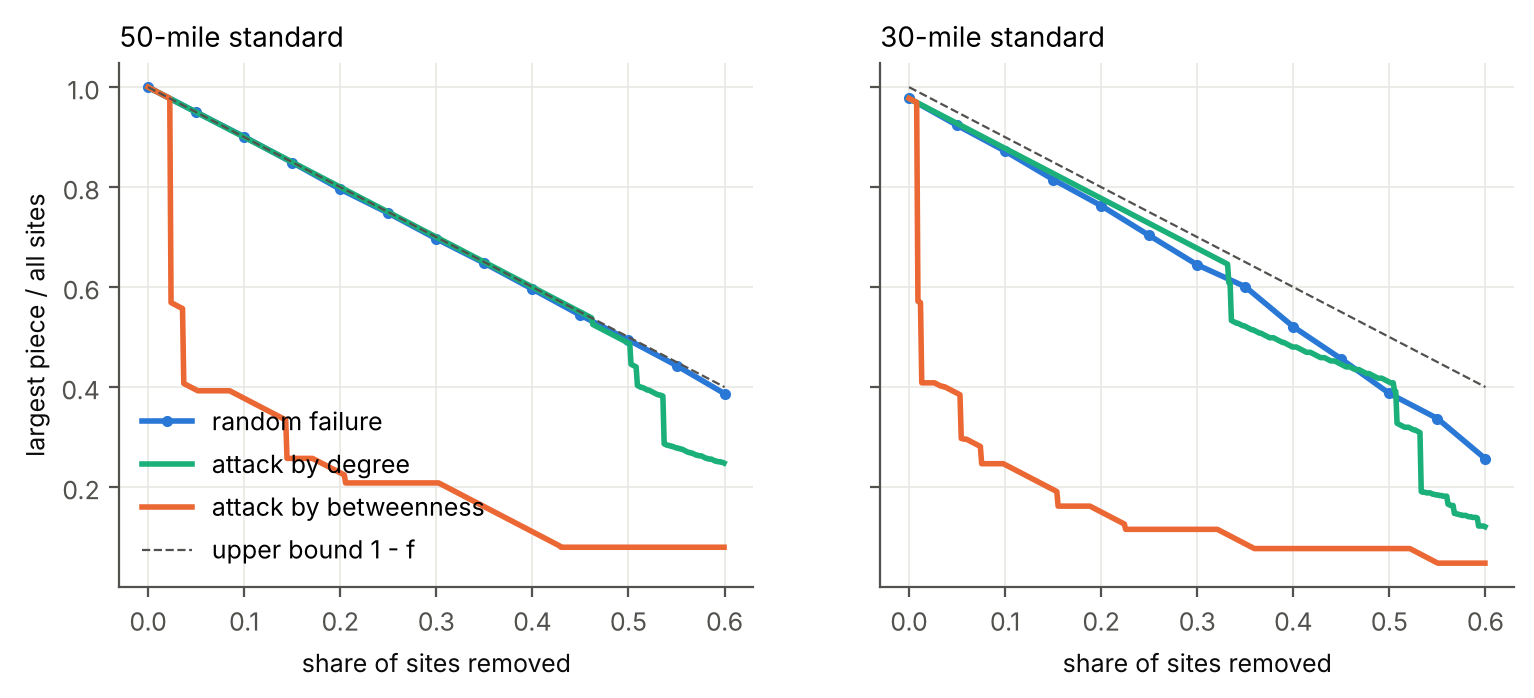

In [5]:
display(t("q2_random_failure.csv"))
display(t("q2_targeted_attack.csv"))
display(t("q2_attack_first15_50mi.csv"))
f("fig4_failure_attack.png")

### 3.2 Coverage is not connectivity

Coverage counts pairs of cities (362 places with 5,000+ people), plain and population-weighted, with two checks:
weights without New York City, and city access capped at 15 miles.

,miles,connectivity,coverage,coverage_weighted,coverage_weighted_excl_NYC,coverage_access15,coverage_weighted_access15
9,10,0.301,0.373,0.511,0.344,0.373,0.511
19,20,0.533,0.595,0.658,0.543,0.588,0.656
24,25,0.537,0.613,0.663,0.559,0.607,0.661
26,27,0.972,0.962,0.984,0.975,0.940,0.979
29,30,0.977,0.962,0.984,0.975,0.940,0.979
34,35,0.991,0.973,0.992,0.987,0.951,0.987
39,40,0.991,0.973,0.992,0.987,0.951,0.987
44,45,0.991,0.973,0.992,0.987,0.951,0.987
45,46,1.000,1.000,1.000,1.000,0.973,0.993
49,50,1.000,1.000,1.000,1.000,0.973,0.993


,name,pop,nearest
0,Ogdensburg city,10064,29.736308
1,Norwich city,7051,21.078531
2,Albion village,5637,19.076975
3,Medina village,6047,18.607458
4,Port Jervis city,8775,17.494966
5,Canton village,7155,12.450472
6,Hamlin CDP,5177,10.984243
7,Fort Drum CDP,15896,9.241879


,miles,name,city,coverage_lost,weighted_lost
0,30,Warren Ford,Warrensburg,0.005402,0.003852
1,30,"Chestertown, NY - Tesla Supercharger",Chestertown,0.005418,0.003854
2,30,Egglefield Bros,Elizabethtown,0.005418,0.003854
3,30,EVolve NY Lewis,Lewis,0.005418,0.003854
4,30,"Peru, NY - Tesla Supercharger",Peru,0.005418,0.003854
5,40,"Chestertown, NY - Tesla Supercharger",Chestertown,0.005448,0.003864
6,40,Frenchies Ford,Massena,0.000046,0.000002


,miles,R_random,R_degree,R_betweenness,Rw_random,Rw_degree,Rw_betweenness
0,50,0.992006,0.976594,0.433280,0.996811,0.931035,0.501598
1,30,0.895562,0.781649,0.345933,0.925001,0.696337,0.428155


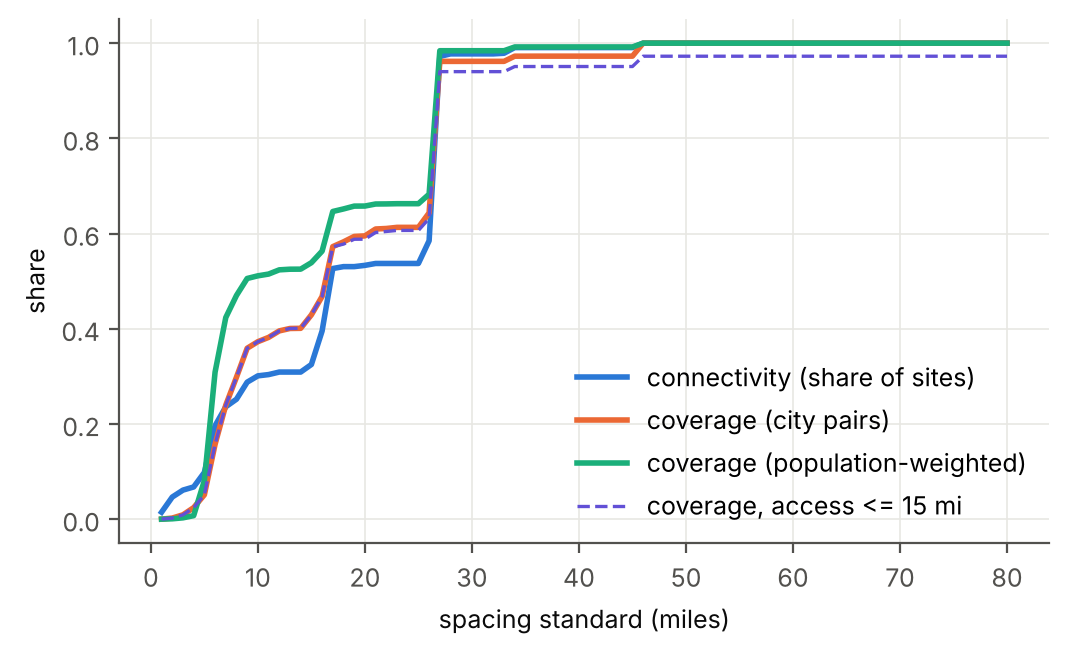

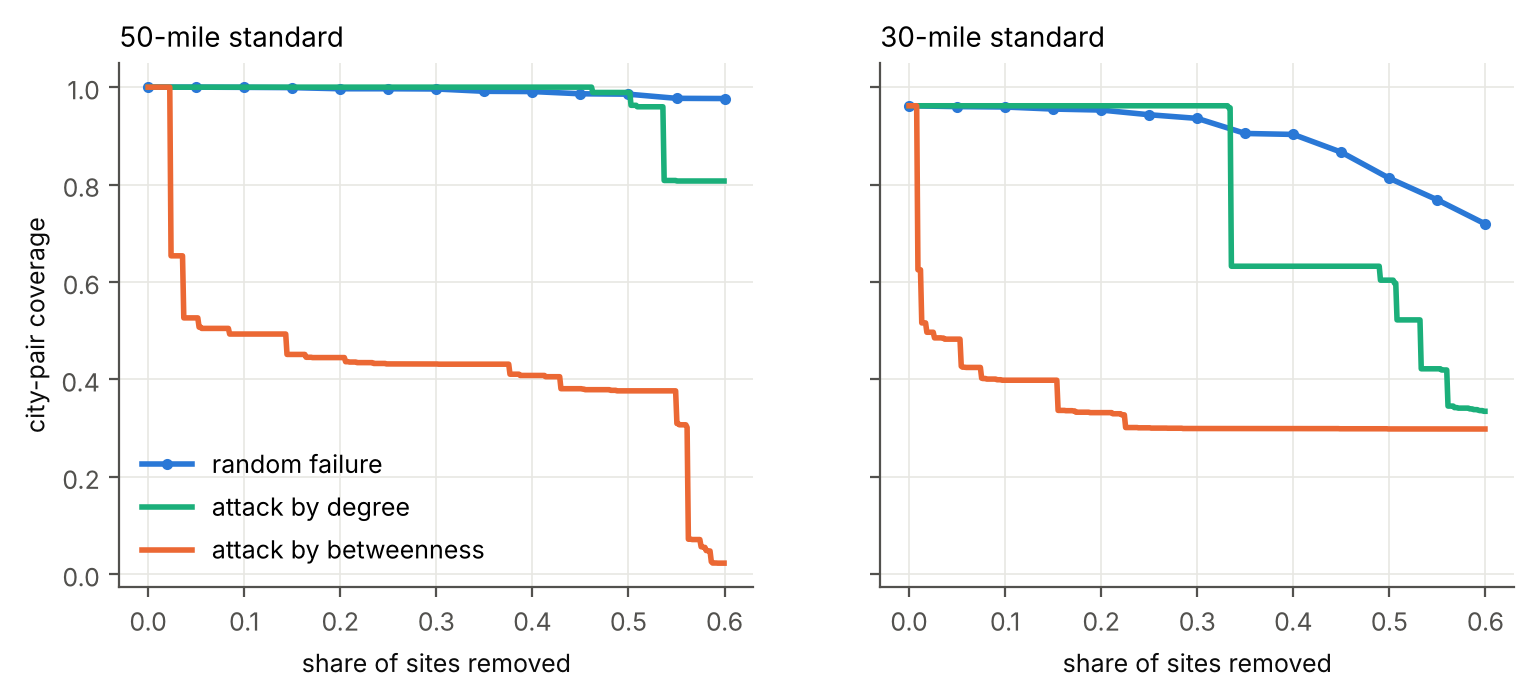

In [6]:
cv = t("coverage_curve.csv")
display(cv[cv["miles"].isin([10, 20, 25, 27, 30, 35, 40, 45, 46, 50])].round(3))
display(t("coverage_farthest_cities.csv"))
display(t("coverage_single_site_loss.csv"))
display(t("coverage_failure_attack.csv"))
f("fig5_coverage_curve.png")
f("figS3_coverage_attack.png")

## 4. Q3: How many new stations does each standard need, and can New York afford them?

`lower_bound` and `new_stations` bracket the true minimum for the whole-network objective. `feasible = False`
means some piece cannot be reached even if every candidate location were upgraded.

,objective,miles,pieces_before,lower_bound,new_stations,feasible,v3_greedy,where,unreachable
0,network,20,32,3.0,16,False,NaN,Stone Ridge; Liberty; Shandaken; Cherry Valley; Ellicottville; Cortland; Aurora; Hammondsport; Silver Creek; Fredoni...,Afton; Alexandria Bay; Cape Vincent; Champlain; Elizabethtown; Hancock; Lake Placid; Lewis; Malone; Massena; North H...
1,network,25,15,5.0,11,False,NaN,Neversink; Downsville; Cherry Valley; Delhi; North River; Newcomb; Jay; Lowville; Turin; Boonville; Clayton,Malone; Massena; Potsdam
2,network,30,5,2.0,3,False,NaN,Newcomb; Lowville; Camden,Malone; Massena; Potsdam
3,network,35,3,2.0,3,True,NaN,Ogdensburg; Gouverneur; Massena,NaN
4,network,40,2,1.0,1,True,NaN,Paul Smiths,NaN
5,network,45,2,1.0,1,True,NaN,Malone,NaN
6,network,50,1,0.0,0,True,NaN,NaN,NaN
7,coverage,20,32,NaN,11,False,8.0,Glen Wild; Cherry Valley; Silver Creek; Groton; Cooperstown; Ellicottville; Cortland; Mount Morris; Kennedy; Earlvil...,Canton village; Fort Drum CDP; Malone village; Massena village; Ogdensburg city; Plattsburgh city; Potsdam village; ...
8,coverage,25,15,NaN,6,False,4.0,Cherry Valley; Jay; North Hudson; Lowville; Turin; Boonville,Canton village; Malone village; Massena village; Ogdensburg city; Potsdam village
9,coverage,30,5,NaN,2,False,3.0,Lowville; Camden,Canton village; Malone village; Massena village; Ogdensburg city; Potsdam village


,objective,miles,lower_bound,new_stations,feasible,where
0,network,20,3.0,15,False,Stone Ridge; Neversink; Shandaken; Cherry Valley; Cattaraugus; Cortland; Aurora; Dunkirk; Olean; Hammondsport; Genes...
1,network,25,5.0,10,False,Neversink; Downsville; Cherry Valley; North River; Newcomb; Jay; Lowville; Turin; Boonville; Clayton
2,network,30,5.0,6,True,Newcomb; Lowville; Camden; Canton; Gouverneur; Hogansburg
3,network,35,2.0,2,True,Paul Smiths; Massena
4,network,40,1.0,1,True,Ogdensburg
5,network,45,1.0,1,True,Malone
6,network,50,0.0,0,True,NaN
7,coverage,20,NaN,11,False,Ellenville; Cherry Valley; Silver Creek; Groton; Cooperstown; Cattaraugus; Cortland; Geneseo; Kennedy; Earlville; Wa...
8,coverage,25,NaN,6,False,Cherry Valley; Peru; North Hudson; Lowville; Turin; Boonville
9,coverage,30,NaN,6,True,Lowville; Camden; Gouverneur; Ogdensburg; Waddington; Hogansburg


cost_level,central,high,low
miles,,,
20,9.14,17.55,5.49
25,6.29,12.07,3.77
30,1.71,3.29,1.03
35,1.71,3.29,1.03
40,0.57,1.10,0.34
45,0.57,1.10,0.34
50,0.00,0.00,0.00


sites the $175M allocation could fund: {'low': 291, 'central': 175, 'high': 91}


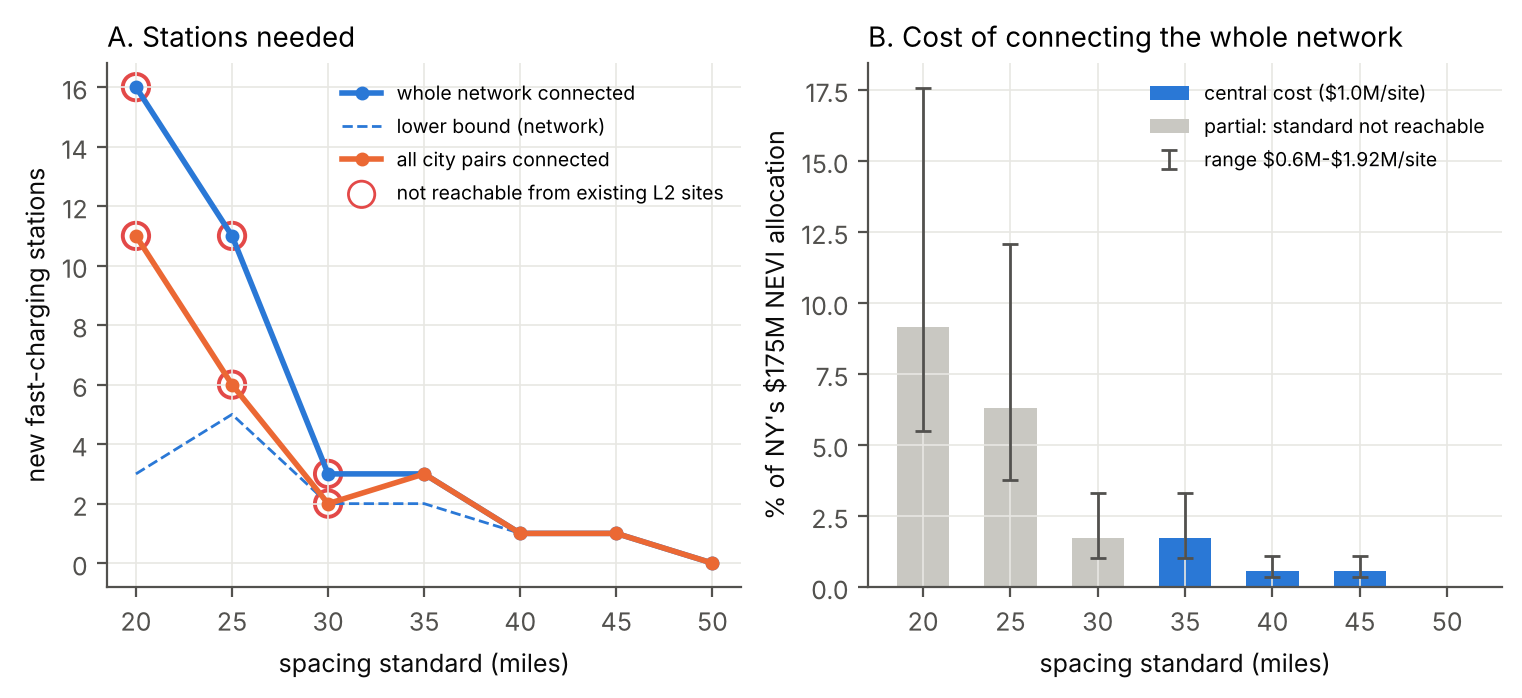

In [7]:
q3 = t("q3_cost_curve.csv")
display(q3)
display(t("q3_sensitivity_factor1.2.csv"))
b = t("q3_budget.csv")
display(b[b["objective"] == "network"].pivot(index="miles", columns="cost_level", values="share_of_NEVI_pct").round(2))
print("sites the $175M allocation could fund:", S["budget"]["sites_affordable"])
f("fig6_cost_curve.png")

### 4.1 Winter (41% range loss at 20°F with heat; AAA 2019)

nominal standard needed for one network in winter: 77.3 miles (road: 73.7)


,nominal_miles,winter_effective_miles,pieces,connectivity,coverage,coverage_weighted
0,30,17.7,43,0.530504,0.576728,0.647849
1,35,20.7,29,0.533156,0.604368,0.660244
2,40,23.6,17,0.537135,0.612999,0.662717
3,45,26.6,8,0.972149,0.961709,0.984074
4,50,29.5,5,0.977454,0.961709,0.984074
5,55,32.5,4,0.978780,0.961754,0.984077
6,60,35.4,3,0.990716,0.972621,0.991970
7,65,38.4,2,0.990716,0.972682,0.991972
8,70,41.3,2,0.990716,0.972682,0.991972
9,75,44.3,2,0.990716,0.972682,0.991972


,nominal_miles,winter_effective_miles,pieces,lower_bound,new_stations,feasible,where
0,50,29.5,5,2,3,False,Newcomb; Lowville; Camden
1,60,35.4,3,2,2,True,Paul Smiths; Massena
2,70,41.3,2,1,1,True,Paul Smiths


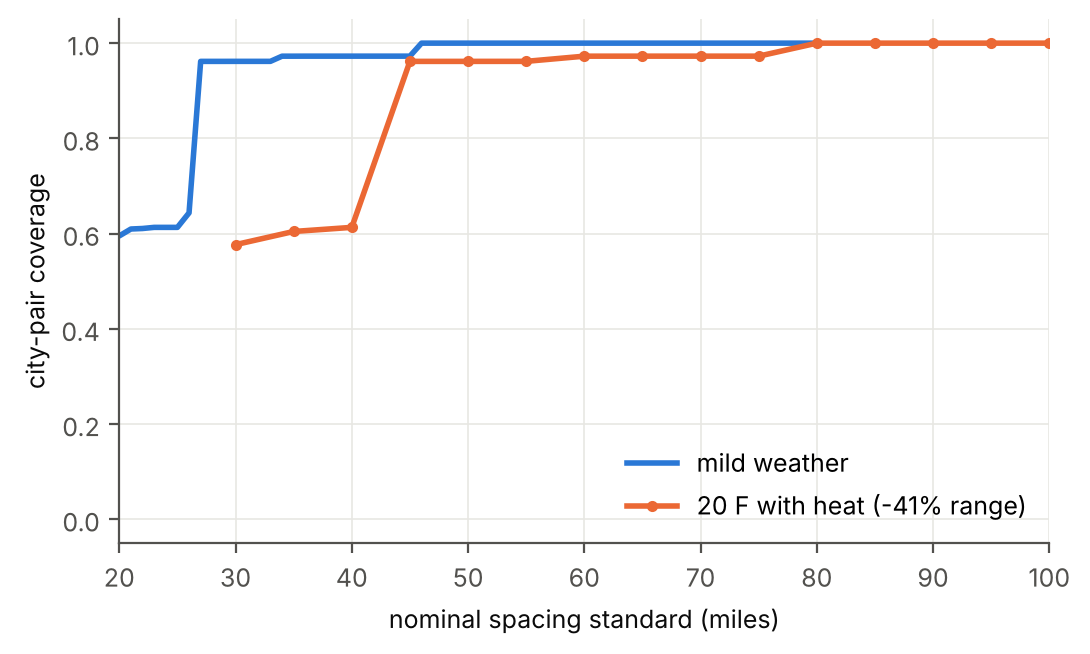

In [8]:
print(f"nominal standard needed for one network in winter: {S['winter_nominal_needed']:.1f} miles (road: {43.5/0.59:.1f})")
display(t("winter.csv"))
display(t("winter_q3.csv"))
f("fig7_winter.png")

## 5. Control: is the network well sited?

,Unnamed: 0,real,random_mean,random_p05,random_p95,share_random_better
0,mst_threshold,45.630,46.944,38.058,56.130,0.43
1,coverage_30,0.962,0.733,0.596,0.946,0.00
2,coverage_40,0.973,0.947,0.654,1.000,0.29
3,weighted_coverage_30,0.984,0.775,0.653,0.975,0.00
4,cut_vertices_30,6.000,9.380,4.950,14.000,0.13
5,pieces_30,5.000,9.690,6.950,14.000,0.00


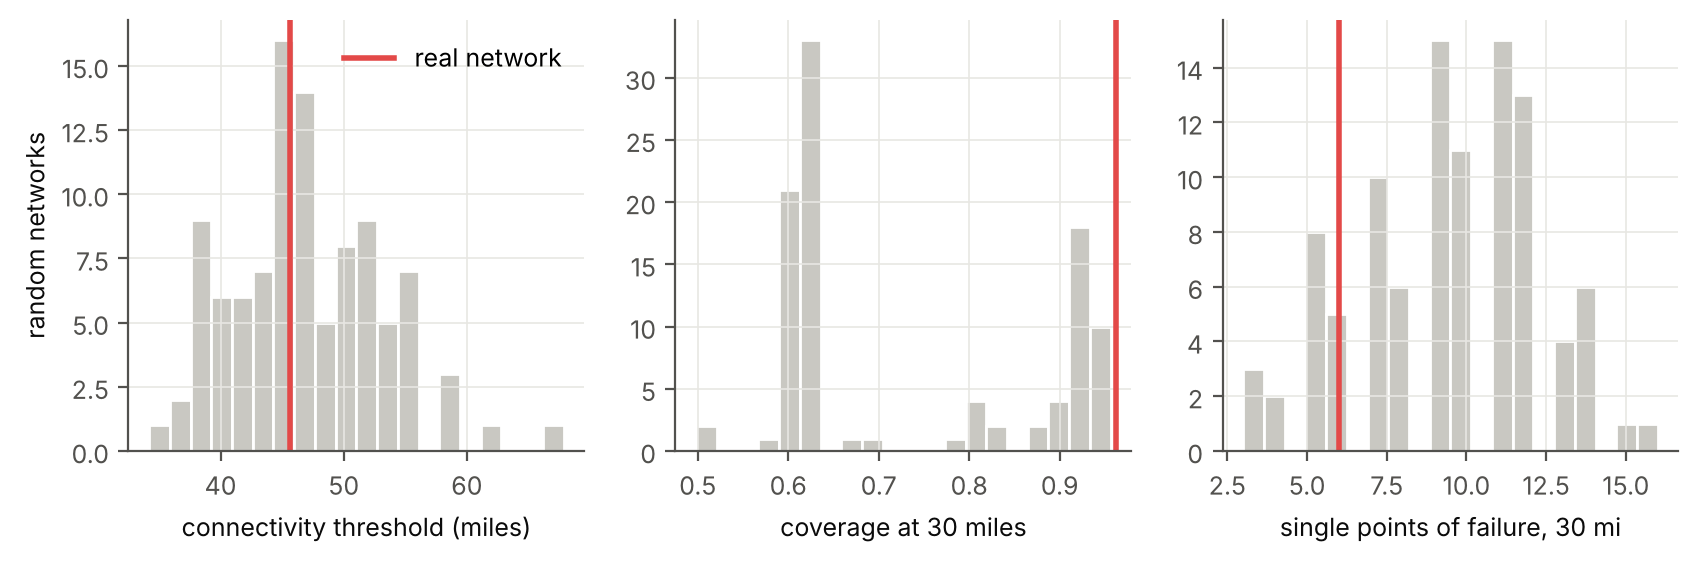

In [9]:
display(t("control_summary.csv").round(3))
f("fig8_control.png")

## 6. Robustness: October 13, 2026 station list

In [10]:
display(t("robustness_snapshot.csv"))

,snapshot,sites,threshold,weakest_link,cut_30,cut_35,cut_45,new_stations_30,new_stations_35,new_stations_40
0,"Sep 23, 2026",754,45.630207,Saranac Lake - Malone,Roscoe; Warrensburg; Chestertown; Elizabethtown; Lewis; Peru,Chestertown; Peru,NaN,3,3,1
1,"Oct 13, 2026",793,45.630207,Saranac Lake - Malone,Roscoe; Warrensburg; Chestertown; Lewis; Peru,Peru,NaN,3,3,1


## 7. Summary

- **Q1.** One network from 43.5 road miles (45.6 calibrated); weakest link Saranac Lake – Malone. The two large
  regions join at 27 miles; the remaining small pieces are all in the Catskills, Adirondacks and North Country.
- **Q2.** At 30 miles six sites are single points of failure, five on the I-87 Northway corridor. They are
  isolated (median degree 7.5 vs 47), not small (median ports 5 vs 4). Betweenness attack removes them first:
  18 removals (2.4%) cut the largest piece below 90% at 50 miles; degree attack does no more than random failure.
- **Coverage.** At 30–45 miles 98–99% of sites but only 96–97% of city pairs are connected; every pair from 46 miles.
- **Q3.** 0 stations at 50 miles, 1 at 40–45, 3 at 35 (all North Country), at most 3.3% of the $175M NEVI
  allocation. 30 miles and below cannot be met from existing public charging locations (feasible at 30 with 6 if
  the detour factor is 1.2).
- **Winter.** One network needs a nominal 74 road miles; at 60 miles nominal two stations (Paul Smiths, Massena) suffice.
- **Control.** Better than all 100 random networks at 30 miles; no better than chance on the overall threshold:
  the North Country gap is geographic.